**本代码通过调用 torch 已有的深度学习框架，简洁的实现线性回归模型**
> 对于线性回归模型的完全代码实现见 DeepLearning/Notebook/linear_regression_model.ipynb \
> 这里采用了已经封装好的库，在代码实现上会更为简洁一点

In [77]:
#导入包
import numpy as np
import torch
from torch.utils import data
from d2l import torch as d2l
from torch import nn

In [78]:
#构造一个数据迭代器读取训练样本的数据
def load_data(data_arrays, batch_size, is_train = True):
    data_set = data.TensorDataset(*data_arrays)
    #针对训练时的数据集需要打乱顺序，设置 shuffle 参数
    return data.DataLoader(data_set, batch_size, shuffle = is_train)

In [79]:
#生成人工数据集
true_w = torch.tensor([2, -3.4])
true_b = 4.2
features, labels = d2l.synthetic_data(true_w, true_b, 1000)

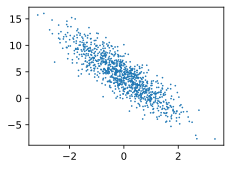

In [80]:
#看一下数据
d2l.set_figsize()
d2l.plt.scatter(features[:, 1].detach().numpy(), labels.detach().numpy(), 0.5)

In [ ]:
#设置变量（数据迭代器）
batch_size = 10
data_iter = load_data((features, labels), batch_size)

In [82]:
#使用框架定义神经网络
#这里的 2 代表输入维度（就是每个样本的特征 x 的个数或者权重 w 的长度）1 代表输出维度（就是只要预测出一个 y 即可）
net = nn.Sequential(nn.Linear(2, 1))

In [83]:
#这里 normal(average, variance) 是用于抽取正态分布下的初始参数
net[0].weight.data.normal_(0, 1)
net[0].bias.data.fill_(0)

tensor([0.])

In [84]:
#取 MSELoss 类里已经定义好的均方差函数作为损失函数
loss = nn.MSELoss()

In [85]:
#使用已经定义的 SGD 模型优化算法（实例化）
trainer = torch.optim.SGD(net.parameters(), lr = 0.01)

In [86]:
#训练循环的代码
num_epochs = 15
for epoch in range(num_epochs):
    for X, y in data_iter:
        #计算误差（这里 loss 函数计算得到的是一个标量，已经 sum() 过了）
        loss_ = loss(net(X), y)
        #设置梯度清零
        trainer.zero_grad()
        #求梯度
        loss_.backward()
        #更新迭代所有参数（步进）
        trainer.step()
    #输出每次训练后结果
    train_res = loss(net(X), y)
    print(f"epoch = {epoch + 1}, loss = {train_res.mean():.10f}")

epoch = 1, loss = 0.6823859811
epoch = 2, loss = 0.0134944795
epoch = 3, loss = 0.0003649181
epoch = 4, loss = 0.0001194669
epoch = 5, loss = 0.0001066512
epoch = 6, loss = 0.0001510221
epoch = 7, loss = 0.0000560681
epoch = 8, loss = 0.0001996977
epoch = 9, loss = 0.0000765093
epoch = 10, loss = 0.0000414305
epoch = 11, loss = 0.0000786770
epoch = 12, loss = 0.0000594402
epoch = 13, loss = 0.0001970234
epoch = 14, loss = 0.0001770910
epoch = 15, loss = 0.0000680205
